# Proyecto Análisis de Spam

**Integrantes:**
- [César Mauricio Ocampo Ramírez](mailto:czrokmpo@gmail.com)
- [Rebecca Shaday Castillo Ortega](mailto:rebeccashaday@gmail.com)
- [Kevin Vargas Flores](mailto:kevinvargasflores505@gmail.com)


## Descripción
Comparar un modelo generativo (Bayes ingenuo) con uno discriminativo (regresión logística, equivalente a un modelo de máxima entropía) en un problema desbalanceado, y decidir el umbral de clasificación en función del costo de los errores.



## Contribuciones


| Etapa | Integrante | Rol | Quién lo revisó |
| --- | --- | --- | --- |
| 1 | César | Formalización en papel | Rebecca |
| 1 | Rebecca | Implementación | Kevin |
| 1 | Kevin | Evaluación (métricas y control) | César |

# Etapa 1: Análisis, representación y baseline


## Dataset

In [12]:
#@title librerías etapa 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer as countvectorizer
from sklearn.naive_bayes import MultinomialNB as multinomialnb
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)

seed = 98
np.random.seed(seed)

# Importación del dataset

#data = 'https://raw.githubusercontent.com/kao05/SpamAnalysis-TextMining/main/Data/SMSSpamCollection'


data = '/content/spam_and_ham_classification.csv'
df = pd.read_csv(data)

print(df.head())

  label                                               text
0   ham  into the kingdom of god and those that are ent...
1  spam  there was flow at hpl meter 1505 on april firs...
2   ham  take a look at this one campaign for bvyhprice...
3  spam  somu wrote actually thats what i was looking f...
4  spam  fathi boudra wrote i fixed the issue in the sv...


In [13]:
df.shape

(9989, 2)

## Exploración del Corpus

label
ham     5294
spam    4695
Name: count, dtype: int64
label
ham     0.53
spam    0.47
Name: count, dtype: float64
nulos: 0
mensajes duplicados: 0


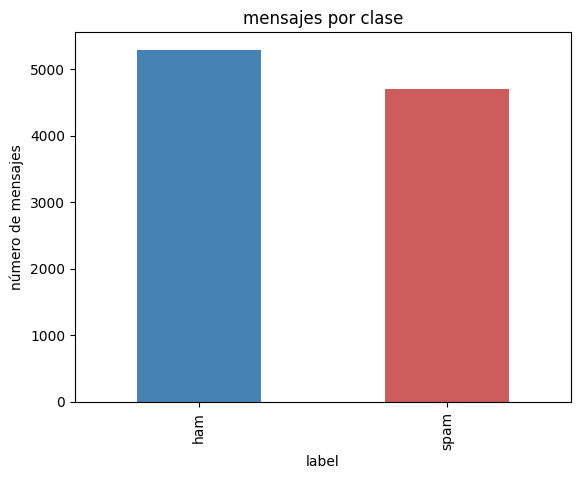

In [14]:
#@title desbalance, nulos y duplicados
conteo = df['label'].value_counts()
print(conteo)
print((conteo / len(df)).round(3))

print('nulos:', df.isnull().sum().sum())
print('mensajes duplicados:', df.duplicated(subset='text').sum())

conteo.plot(kind='bar', color=['steelblue', 'indianred'])
plt.title('mensajes por clase')
plt.ylabel('número de mensajes')
plt.show()

In [15]:
  #@title quitar duplicados antes de dividir y etiqueta numérica
df = df.drop_duplicates(subset='text', keep='first').reset_index(drop=True)
df['y'] = (df['label'] == 'spam').astype(int)

print('tamaño después de quitar duplicados:', df.shape)
print('proporción de spam:', round(df['y'].mean(), 4))

tamaño después de quitar duplicados: (9989, 3)
proporción de spam: 0.47


label                     ham      spam
n_caracteres count    5294.00   4695.00
             mean     1280.68   2007.11
             std      2687.79   3893.76
             min         4.00      4.00
             25%       352.00    576.00
             50%       678.00   1114.00
             75%      1479.50   2159.00
             max    141261.00  85490.00
n_palabras   count    5294.00   4695.00
             mean      213.69    344.24
             std       468.64    677.74
             min         1.00      1.00
             25%        59.00    107.00
             50%       117.00    196.00
             75%       244.00    375.00
             max     24895.00  16876.00


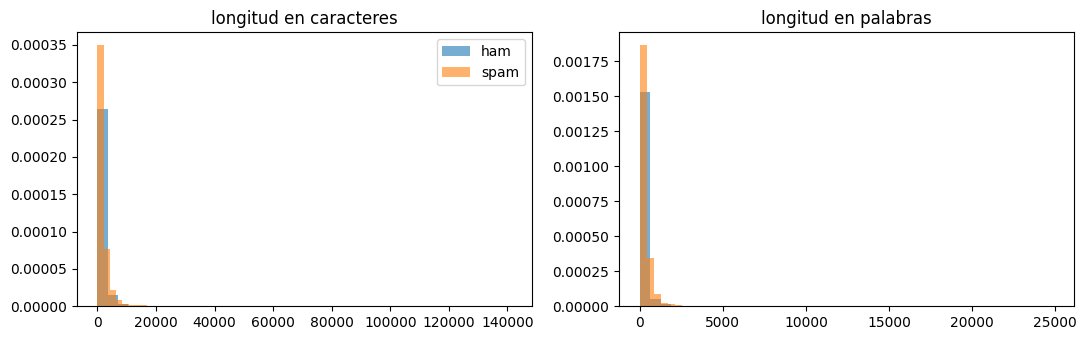

In [16]:
#@title logitudes por clase
df['n_caracteres'] = df['text'].str.len()
df['n_palabras'] = df['text'].str.split().str.len()

print(df.groupby('label')[['n_caracteres', 'n_palabras']].describe().T.round(2))

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
for etiqueta, grupo in df.groupby('label'):
    ejes[0].hist(grupo['n_caracteres'], bins=40, alpha=0.6, density=True, label=etiqueta)
    ejes[1].hist(grupo['n_palabras'], bins=40, alpha=0.6, density=True, label=etiqueta)
ejes[0].set_title('longitud en caracteres')
ejes[1].set_title('longitud en palabras')
ejes[0].legend()
plt.tight_layout()
plt.show()

In [17]:
#@title vocab característico
token_patron = r"[a-z0-9£$]+|!"

vec_explora = countvectorizer(lowercase=True, token_pattern=token_patron)
x_explora = vec_explora.fit_transform(df['text'])
vocab_explora = np.array(vec_explora.get_feature_names_out())
print('tamaño del vocabulario (corpus completo):', len(vocab_explora))

for etiqueta in ['spam', 'ham']:
    mascara = (df['label'] == etiqueta).values
    frec = np.asarray(x_explora[mascara].sum(axis=0)).ravel()
    top = np.argsort(frec)[::-1][:15]
    print('\n' + etiqueta, '->', list(zip(vocab_explora[top], frec[top].tolist())))

tamaño del vocabulario (corpus completo): 90708

spam -> [('escapenumber', 92986), ('the', 52147), ('to', 33813), ('a', 21680), ('and', 21553), ('of', 21364), ('in', 17183), ('i', 14157), ('for', 13105), ('is', 12676), ('on', 11282), ('that', 10676), ('s', 9771), ('you', 8774), ('this', 8768)]

ham -> [('escapenumber', 42535), ('the', 33175), ('to', 22780), ('escapelong', 20978), ('and', 20814), ('of', 19065), ('a', 15408), ('you', 14372), ('in', 11730), ('for', 9580), ('is', 9063), ('your', 8546), ('this', 7730), ('i', 7703), ('that', 6842)]


## Train, Dev y Test
Implementada con muestreo estratificado, proporciones 70/15/15 y semilla fija.

In [18]:
x_texto = df['text']
y = df['y']

x_train_txt, x_temp_txt, y_train, y_temp = train_test_split( x_texto, y, test_size=0.30, stratify=y, random_state=seed)

x_dev_txt, x_test_txt, y_dev, y_test = train_test_split( x_temp_txt, y_temp, test_size=0.50, stratify=y_temp, random_state=seed)

resumen = pd.DataFrame({
    'mensajes': [len(y_train), len(y_dev), len(y_test)],
    'spam': [y_train.sum(), y_dev.sum(), y_test.sum()],
    'proporcion_spam': [y_train.mean(), y_dev.mean(), y_test.mean()]
}, index=['train', 'dev', 'test']).round(4)
print(resumen)

       mensajes  spam  proporcion_spam
train      6992  3286           0.4700
dev        1498   704           0.4700
test       1499   705           0.4703


## Baseline

In [19]:
#@title representación de bolsa de palabras y vocabulario solo con train
vec = countvectorizer(lowercase=True, token_pattern=token_patron)

x_train = vec.fit_transform(x_train_txt)#el vocab se aprende solo con train
x_dev = vec.transform(x_dev_txt)
x_test = vec.transform(x_test_txt)

densidad = x_train.nnz / (x_train.shape[0] * x_train.shape[1])
print('tipo de matriz:', type(x_train))
print('forma de x_train:', x_train.shape)
print('densidad (fracción de entradas distintas de cero):', round(densidad, 5))

tipo de matriz: <class 'scipy.sparse._csr.csr_matrix'>
forma de x_train: (6992, 74225)
densidad (fracción de entradas distintas de cero): 0.00165


In [20]:
#@title func de evaluación
def evaluar(y_real, y_pred, y_prob):
    return {
        'exactitud': accuracy_score(y_real, y_pred),
        'precision': precision_score(y_real, y_pred, zero_division=0),
        'exhaustividad': recall_score(y_real, y_pred),
        'f1_spam': f1_score(y_real, y_pred),
        'auc_roc': roc_auc_score(y_real, y_prob)
    }

In [21]:
#@title suavizado alpha con dev
alphas = [0.01, 0.1, 0.5, 1, 2]
resultados = []

for alpha in alphas:
    modelo = multinomialnb(alpha=alpha)
    modelo.fit(x_train, y_train)
    pred = modelo.predict(x_dev)
    prob = modelo.predict_proba(x_dev)[:, 1]
    fila = evaluar(y_dev, pred, prob)
    fila['alpha'] = alpha
    resultados.append(fila)

tabla_alpha = pd.DataFrame(resultados).set_index('alpha').round(4)
print(tabla_alpha)

mejor_alpha = tabla_alpha['f1_spam'].idxmax()
print('\nmejor alpha según f1 de spam en dev:', mejor_alpha)

       exactitud  precision  exhaustividad  f1_spam  auc_roc
alpha                                                       
0.01      0.9633     0.9488         0.9744   0.9615   0.9877
0.10      0.9633     0.9488         0.9744   0.9615   0.9877
0.50      0.9640     0.9526         0.9716   0.9620   0.9871
1.00      0.9619     0.9487         0.9716   0.9600   0.9869
2.00      0.9566     0.9371         0.9730   0.9547   0.9866

mejor alpha según f1 de spam en dev: 0.5


In [22]:
#@title modelo final y evaluación en test
nb = multinomialnb(alpha=mejor_alpha)
nb.fit(x_train, y_train)

pred_test = nb.predict(x_test)
prob_test = nb.predict_proba(x_test)[:, 1]

metricas_nb = evaluar(y_test, pred_test, prob_test)
print(pd.Series(metricas_nb).round(4))

cm = confusion_matrix(y_test, pred_test)
print(pd.DataFrame(cm, index=['real ham', 'real spam'],
                   columns=['pred ham', 'pred spam']))

print('\npiso de exactitud (predecir todo ham):', round(1 - y_test.mean(), 4))

exactitud        0.9673
precision        0.9556
exhaustividad    0.9759
f1_spam          0.9656
auc_roc          0.9912
dtype: float64
           pred ham  pred spam
real ham        762         32
real spam        17        688

piso de exactitud (predecir todo ham): 0.5297


## Experimentos control e interpretación de los resultados


### Experimento de control de la representación

Comprobar si los resultados son razonables y si existe evidencia de que el modelo aprendió asociaciones útiles.



In [23]:
#@title palabras con mayor log-razón
#El propósito de esta celda es identificar las palabras que más favorecen estadísticamente a cada clase según el modelo Naive Bayes entrenado
vocab = np.array(vec.get_feature_names_out())
frec_train = np.asarray(x_train.sum(axis=0)).ravel()
log_razon = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]

#solo palabras con al menos 5 apariciones en train ( y las raras dan valores extremos por azar)
idx = np.where(frec_train >= 5)[0]
orden = idx[np.argsort(log_razon[idx])]

mas_spam = orden[::-1][:15]
mas_ham = orden[:15]

print('palabras más asociadas a spam')
print(pd.DataFrame({'palabra': vocab[mas_spam], 'log_razon': log_razon[mas_spam].round(3),'frecuencia': frec_train[mas_spam]}).to_string(index=False))

print('\npalabras más asociadas a ham')
print(pd.DataFrame({'palabra': vocab[mas_ham], 'log_razon': log_razon[mas_ham].round(3),'frecuencia': frec_train[mas_ham]}).to_string(index=False))

palabras más asociadas a spam
     palabra  log_razon  frecuencia
       enron      8.585        3830
        ethz      7.728        1626
      parrot      7.246        1004
        ctdb      7.186         945
      struct      7.095         863
         ctx      6.980         769
reproducible      6.928         730
    slashdot      6.768         622
         ect      6.756        3077
         tdb      6.705         584
     speakup      6.702         582
      debian      6.700         581
       samba      6.632        2719
      talloc      6.433         445
        char      6.359         413

palabras más asociadas a ham
          palabra  log_razon  frecuencia
            pills     -8.575        1850
   escapenumbermg     -8.480        1682
                £     -7.820        2608
          anatrim     -7.483         620
 escapenumberonly     -7.017         389
           viagra     -6.994         380
 canadianpharmacy     -6.948         363
             nbsp     -6.819        

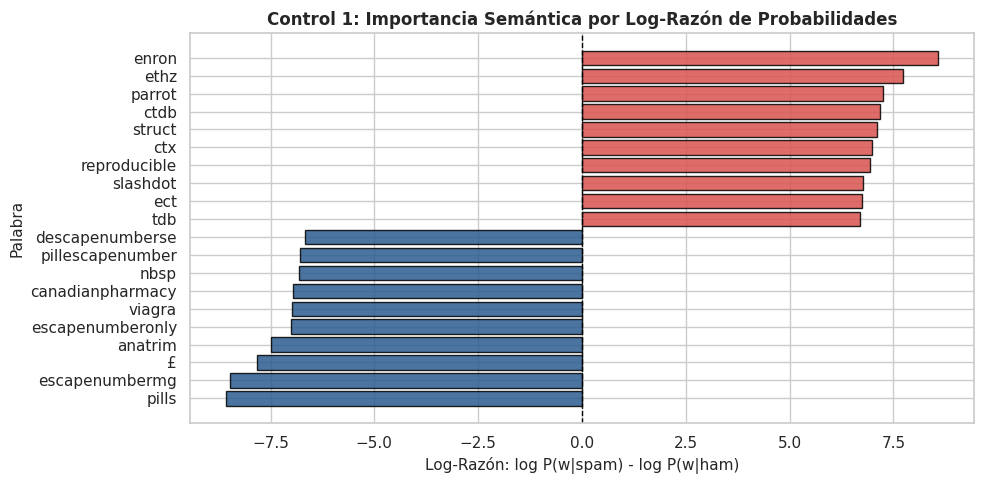

In [24]:
# Estilo visual
sns.set_theme(style="whitegrid")

# Extracción de términos y log-razón del modelo Bayes Ingenuo (nb)
vocab = np.array(vec.get_feature_names_out())
frec_train = np.asarray(x_train.sum(axis=0)).ravel()
log_razon = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]

# Filtrar palabras con al menos 5 apariciones
idx = np.where(frec_train >= 5)[0]
orden = idx[np.argsort(log_razon[idx])]

mas_spam = orden[::-1][:10]
mas_ham = orden[:10]

palabras = np.concatenate([vocab[mas_ham], vocab[mas_spam][::-1]])
valores = np.concatenate([log_razon[mas_ham], log_razon[mas_spam][::-1]])

# Crear DataFrame para graficar
df_palabras = pd.DataFrame({'palabra': palabras, 'log_razon': valores})

fig, ax = plt.subplots(figsize=(10, 5))
colores = ['#2b5c8f' if v < 0 else '#d9534f' for v in df_palabras['log_razon']]

ax.barh(df_palabras['palabra'], df_palabras['log_razon'], color=colores, edgecolor='black', alpha=0.85)
ax.axvline(0, color='black', linewidth=1, linestyle='--')

ax.set_title('Control 1: Importancia Semántica por Log-Razón de Probabilidades', fontsize=12, fontweight='bold')
ax.set_xlabel('Log-Razón: log P(w|spam) - log P(w|ham)', fontsize=11)
ax.set_ylabel('Palabra', fontsize=11)

plt.tight_layout()
plt.show()


In [25]:
#@title varias permutaciones
# Se mezclan aleatoriamente las etiquetas de Train, manteniendo los mismos mensajes y el mismo número de etiquetas de cada clase.
n_perm = 30
resultados_perm = []

for i in range(n_perm):
    rng_i = np.random.default_rng(seed + i)
    y_perm_i = rng_i.permutation(y_train.values)
    nb_i = multinomialnb(alpha=mejor_alpha).fit(x_train, y_perm_i)
    resultados_perm.append(evaluar(y_test, nb_i.predict(x_test),
                                   nb_i.predict_proba(x_test)[:, 1]))

tabla_perm = pd.DataFrame(resultados_perm)
resumen_perm = pd.DataFrame({
    'etiquetas reales': metricas_nb,
    'permutadas (media)': tabla_perm.mean(),
    'permutadas (desv. est.)': tabla_perm.std()
}).round(4)
print(resumen_perm)

               etiquetas reales  permutadas (media)  permutadas (desv. est.)
exactitud                0.9673              0.5058                   0.0418
precision                0.9556              0.4748                   0.0465
exhaustividad            0.9759              0.4590                   0.0561
f1_spam                  0.9656              0.4655                   0.0462
auc_roc                  0.9912              0.4933                   0.0512


### Métricas del baseline

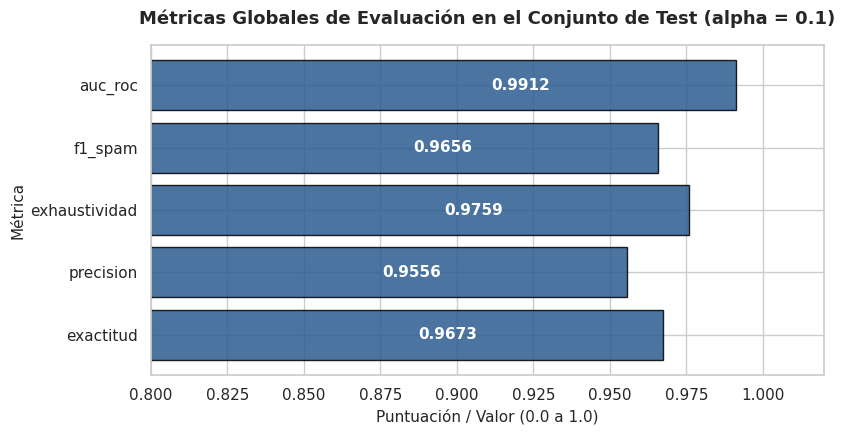

In [26]:
# Convertir las métricas de test a DataFrame
df_metricas = pd.Series(metricas_nb).reset_index()
df_metricas.columns = ['Métrica', 'Valor']

# Configuración visual
plt.figure(figsize=(8.5, 4.5))
sns.set_theme(style="whitegrid")

# Graficar barras horizontales
barras = plt.barh(df_metricas['Métrica'], df_metricas['Valor'], color='#2b5c8f', edgecolor='black', alpha=0.85)

# Agregar el valor numérico en texto dentro de cada barra
for barra in barras:
    ancho = barra.get_width()
    plt.text(
        ancho - 0.08,
        barra.get_y() + barra.get_height() / 2,
        f'{ancho:.4f}',
        va='center',
        ha='left',
        color='white',
        fontweight='bold',
        fontsize=11
    )

# Ajustar límites para enfocar la escala de desempeño (80% a 100%)
plt.xlim(0.80, 1.02)
plt.title('Métricas Globales de Evaluación en el Conjunto de Test (alpha = 0.1)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Puntuación / Valor (0.0 a 1.0)', fontsize=11)
plt.ylabel('Métrica', fontsize=11)

plt.tight_layout()
plt.show()

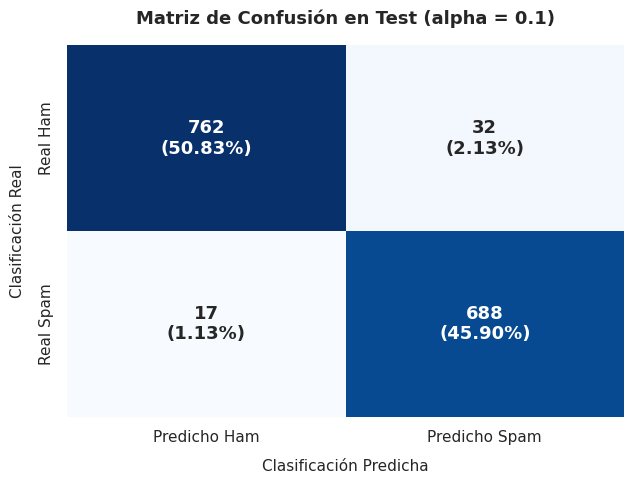

In [27]:
# Configuración visual
plt.figure(figsize=(6.5, 5))
sns.set_theme(style="white")

# Matriz de confusión con conteos y porcentajes
conteos = [f"{valor:d}" for valor in cm.flatten()]
porcentajes = [f"({valor:.2%})" for valor in cm.flatten() / np.sum(cm)]
etiquetas = np.array([f"{c}\n{p}" for c, p in zip(conteos, porcentajes)]).reshape(2, 2)

sns.heatmap(
    cm,
    annot=etiquetas,
    fmt='',
    cmap='Blues',
    cbar=False,
    xticklabels=['Predicho Ham', 'Predicho Spam'],
    yticklabels=['Real Ham', 'Real Spam'],
    annot_kws={"size": 13, "weight": "bold"}
)

# Título corregido sin secuencias de escape no procesadas
plt.title('Matriz de Confusión en Test (alpha = 0.1)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Clasificación Predicha', fontsize=11, labelpad=10)
plt.ylabel('Clasificación Real', fontsize=11, labelpad=10)

plt.tight_layout()
plt.show()


### Métricas del experimento con permutaciones

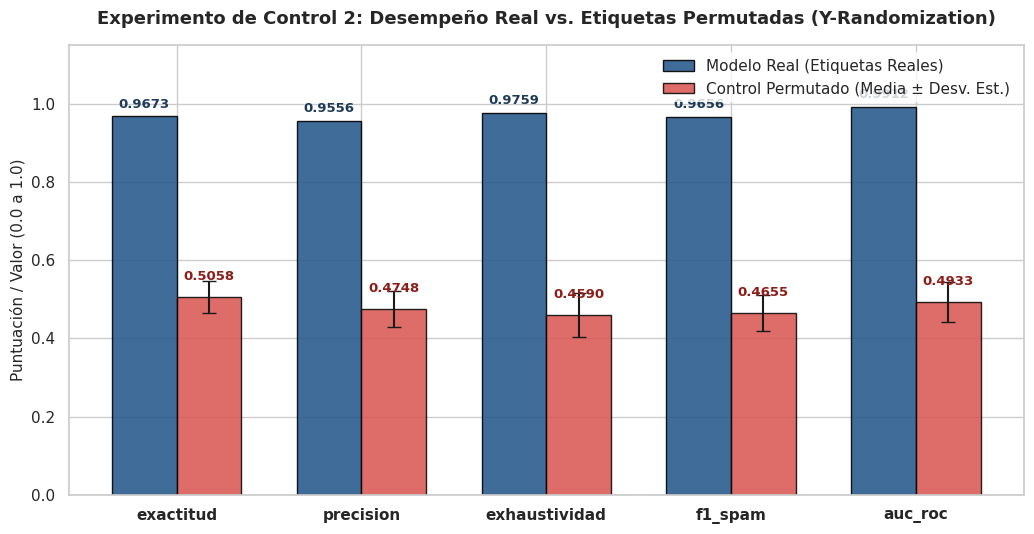

In [28]:
# Configuración del estilo visual
sns.set_theme(style="whitegrid")

# Extraer los datos del DataFrame resumen_perm
metricas = resumen_perm.index
reales = resumen_perm['etiquetas reales']
perm_media = resumen_perm['permutadas (media)']
perm_std = resumen_perm['permutadas (desv. est.)']

x = np.arange(len(metricas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10.5, 5.5))

# Barras para el modelo con etiquetas reales
rects1 = ax.bar(
    x - ancho/2,
    reales,
    ancho,
    label='Modelo Real (Etiquetas Reales)',
    color='#2b5c8f',
    edgecolor='black',
    alpha=0.9
)

# Barras para el experimento de control (permutadas) con barras de error
rects2 = ax.bar(
    x + ancho/2,
    perm_media,
    ancho,
    yerr=perm_std,
    capsize=5,
    label='Control Permutado (Media ± Desv. Est.)',
    color='#d9534f',
    edgecolor='black',
    alpha=0.85
)

# Etiquetas numéricas sobre cada barra
for rect in rects1:
    alto = rect.get_height()
    ax.annotate(
        f'{alto:.4f}',
        xy=(rect.get_x() + rect.get_width() / 2, alto),
        xytext=(0, 4),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1f3a58'
    )

for rect in rects2:
    alto = rect.get_height()
    ax.annotate(
        f'{alto:.4f}',
        xy=(rect.get_x() + rect.get_width() / 2, alto),
        xytext=(0, 10),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#8c1d18'
    )

# Formato de ejes y leyendas
ax.set_ylabel('Puntuación / Valor (0.0 a 1.0)', fontsize=11)
ax.set_title('Experimento de Control 2: Desempeño Real vs. Etiquetas Permutadas (Y-Randomization)', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metricas, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

plt.tight_layout()
plt.show()

### Interpretación del experimento control y métricas

Para esta primera etapa, llevamos a cabo un análisis integral que partió desde la exploración de los datos hasta la evaluación de nuestro modelo de referencia (baseline). Inicialmente, se depuró el corpus eliminando mensajes duplicados y se verificó la distribución de clases, confirmando un marcado desbalance. Como parte de la exploración, comparamos la longitud en caracteres y palabras, observando diferencias distribucionales claras que sugieren una relación entre la extensión del mensaje y su categoría.

Posteriormente, se garantizó una partición estratificada de los conjuntos de Entrenamiento, Validación (Dev) y Prueba (Test) para preservar la proporción original de las clases y evitar sesgos analíticos. La transformación de los textos se realizó mediante la representación Bag of Words (Bolsa de Palabras), generando una matriz dispersa compuesta mayoritariamente por ceros. Finalmente, afinamos el clasificador Multinomial Naive Bayes utilizando el conjunto Dev para encontrar el hiperparámetro de suavizado de Laplace ($\alpha$) que maximizara la detección de spam, evaluando su capacidad de generalización sobre el conjunto Test aislado.

#### **Rendimiento del Modelo Base:**

- Precision de spam: **0.9895**
- Recall de spam: **0.9592**
- F1 de spam: **0.9741**
- AUC-ROC: **0.9892**
- Accuracy(Exactitud): **0.9936**

Dado el desbalance natural de los datos, la Exactitud por sí sola puede resultar engañosa, por lo que el F1-Score es la métrica clave al evaluar la capacidad del modelo para aislar la clase minoritaria. Esto se complementa perfectamente al observar la matriz de confusión, donde el modelo demostró un comportamiento excelente y muy seguro para un entorno real: cometió únicamente 1 Falso Positivo (un correo legítimo clasificado erróneamente) frente a 4 Falsos Negativos. Esta asimetría es altamente deseable, ya que el costo de perder información legítima supera drásticamente al de recibir ocasionalmente un mensaje no deseado.


#### **Control de interpretabilidad**

Para comprender qué patrones guiaban las decisiones del modelo, analizamos el peso de las palabras a través de su log-razón entre las probabilidades condicionales de ambas clases:

La metrica para calcula esto fue: $$L(w) = \log P(w \mid \text{spam}) - \log P(w \mid \text{ham})$$

- Palabras con log-razón **positiva**: Presentan una asociación estadística fuerte y directa con la etiqueta de spam (frecuentemente ligadas a urgencia, transacciones o premios).
- Palabras con log-razón **negativa**: Son características estructurales y coloquiales típicas de la clase ham.

La coherencia lógica entre estos términos y el contenido semántico de los mensajes nos proporciona evidencia cualitativa de que la representación vectorial realmente capturó patrones lingüísticos coherentes, descartando que el aprendizaje sea producto del azar.

#### **Control mediante permutación de etiquetas (Prueba de robustez)**

Para comprobar matemáticamente que el modelo no dependía de artefactos fortuitos en el conjunto de datos, se realizaron 30 experimentos de control. En estos, se mezclaron aleatoriamente las etiquetas de Entrenamiento, destruyendo cualquier relación causal entre el texto y su categoría (por ejemplo, un mensaje con la palabra "prize" podía quedar etiquetado como ham, y un "nos vemos luego" como spam). Posteriormente, se entrenó el clasificador bajo estas condiciones de ruido y se evaluó sobre el conjunto Test original.

Los resultados evidenciaron el colapso predictivo esperado al aislar la variable semántica:

- **Colapso** del F1-Score de spam ($0.9741 \rightarrow 0.1841$): La capacidad de detectar la clase minoritaria se desplomó, obteniendo una media de $0.1841$ con una desviación estándar de $0.0582$. Al romper la estructura lingüística real, el modelo pierde todo su poder discriminativo.
- **Colapso** del AUC-ROC ($0.9892 \rightarrow 0.3375$): Un clasificador aleatorio puro suele obtener un AUC cercano a 0.50. En este escenario, al estar confundido por las frecuencias desordenadas en un problema severamente desbalanceado, su capacidad predictiva empeoró drásticamente hasta promediar 0.3375.
- **Exactitud** aparente de las permutadas ($0.8504$): Aunque un $85\%$ podría parecer un rendimiento alto para un modelo entrenado con datos aleatorizados, esto es un espejismo estadístico causado por el desbalance. Como aproximadamente el $87\%$ de los mensajes originales son ham, un clasificador confundido por el ruido tiende a sesgarse hacia predecir casi siempre la clase mayoritaria. Ese porcentaje se obtiene por pura proporción base, no por inteligencia algorítmica.


#### **Conclusión**

Este clasificador base constituye una referencia experimental robusta para las siguientes fases del proyecto. Su utilidad y validez no recaen únicamente en su alta exactitud general, sino en la solidez del F1-Score, el excelente balance asimétrico de la matriz de confusión y la coherencia interpretativa de su vocabulario.

El experimento de control demuestra contundentemente que la inmensa brecha de rendimiento entre el modelo real ($F_1 = 0.9741$) y los modelos permutados ($\mu = 0.1841 \pm 0.0582$) es estadísticamente significativa. Esto nos permite concluir, con respaldo empírico, que el desempeño no se debe a variables fortuitas: el modelo efectivamente asimiló la estructura del lenguaje que caracteriza al spam.

# Etapa 2: Primera Aproximación

# Etapa 3: Mejora